In [33]:
import librosa
import soundfile as sf
import os
import numpy as np
import matplotlib.pyplot as plt
import pyloudnorm as pyln
import noisereduce as nr

In [34]:
input_directory = "Data/genres_original/blues"
output_directory = "OutputData/blues"

In [35]:
#Standardize the sampling rate across all audio files to 22050Hz
target_sample_rate = 22050  # The sample rate you want to check against

# Initialize counters
count_need_normalize = 0
count_valid = 0

# Iterate through all files in the directory and check their sample rates
for filename in os.listdir(input_directory):
    if filename.endswith(".wav"):  # Modify this to handle other formats (e.g., .mp3)
        input_path = os.path.join(input_directory, filename)
        try:
            # Load the audio file to get its sample rate
            _, sr = librosa.load(input_path, sr=None)  # sr=None keeps the original sample rate
            if sr != target_sample_rate:
                print(f"File {input_path} has sample rate {sr} Hz (not {target_sample_rate} Hz).")
                count_need_normalize += 1  # Count files that need normalization
            else:
                count_valid += 1  # Count files with the correct sample rate
        except Exception as e:
            print(f"Error loading {input_path}: {e}")

# Print the results
if count_need_normalize > 0:
    print(f"The dataset needs to Standardize {count_need_normalize} file(s).")
else:
    print(f"The dataset does not need to Standardize. All {count_valid} audios are {target_sample_rate} Hz.")


The dataset does not need to Standardize. All 100 audios are 22050 Hz.


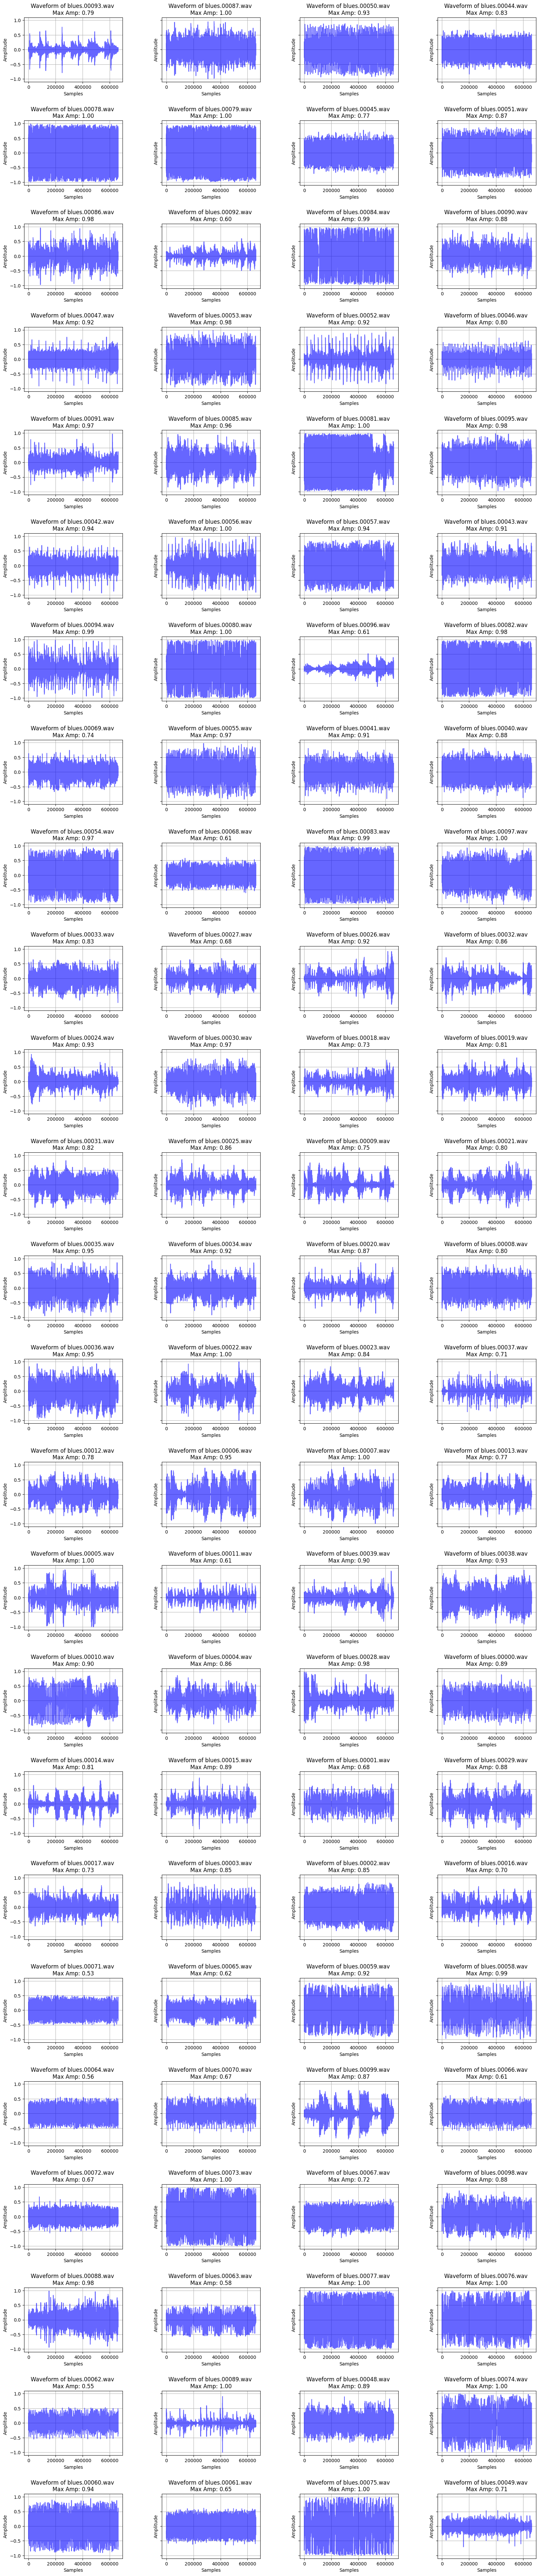

In [36]:
# Create a list to store the waveforms, filenames, and max amplitudes for later plotting
waveforms = []
filenames = []
max_amplitudes = []

# Iterate through all files in the directory (don't normalize yet)
for filename in os.listdir(input_directory):
    if filename.endswith(".wav"):  # Modify this to handle other formats (e.g., .mp3)
        input_path = os.path.join(input_directory, filename)

        try:
            # Load the audio file
            audio_data, sr = librosa.load(input_path, sr=None)  # sr=None keeps the original sample rate
            
            # Find the peak amplitude in the audio
            peak_amplitude = np.max(np.abs(audio_data))
            
            # Append data for later plotting
            waveforms.append(audio_data)
            filenames.append(filename)
            max_amplitudes.append(peak_amplitude)

        except Exception as e:
            print(f"Error processing {input_path}: {e}")

# Determine the number of files and rows required for the plot
n_files = len(waveforms)
n_cols = 4  # Number of columns in the plot grid
n_rows = (n_files + n_cols - 1) // n_cols  # Calculate the number of rows

# Create a figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4), sharey=True)

# Flatten axes array for easy iteration if it's multidimensional
axes = axes.flatten()

# Plot each waveform
for i in range(n_files):
    axes[i].plot(waveforms[i], color='blue', alpha=0.6)
    axes[i].set_title(f"Waveform of {filenames[i]} \nMax Amp: {max_amplitudes[i]:.2f}")
    axes[i].set_xlabel("Samples")
    axes[i].set_ylabel("Amplitude")
    axes[i].grid(True)

# Remove empty subplots (if the number of files is not a perfect multiple of n_cols)
for i in range(n_files, len(axes)):
    axes[i].axis('off')

# Adjust layout for better spacing
plt.subplots_adjust(wspace=0.4, hspace=0.6)

In [37]:
# Function to print the sample rate of an audio file
def print_sample_rate(input_file):
    try:
        # Load the audio file to get its sample rate
        _, sr = librosa.load(input_file, sr=None)  # sr=None keeps the original sample rate
        print(f"Sample rate of {input_file}: {sr} Hz")
    except Exception as e:
        print(f"Error loading {input_file}: {e}")

# Directory containing the audio files
input_directory = 'Data/genres_original/blues'  # Replace with your input directory

# Iterate through all files in the directory and print their sample rates
for filename in os.listdir(input_directory):
    if filename.endswith(".wav"):  # You can modify this to handle other formats (e.g., .mp3)
        input_path = os.path.join(input_directory, filename)
        print_sample_rate(input_path)

Sample rate of Data/genres_original/blues/blues.00093.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00087.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00050.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00044.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00078.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00079.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00045.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00051.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00086.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00092.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00084.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00090.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00047.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00053.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.

In [38]:
# Function to print the sample rate of an audio file
def print_sample_rate(input_file):
    try:
        # Load the audio file to get its sample rate
        _, sr = librosa.load(input_file, sr=None)  # sr=None keeps the original sample rate
        print(f"Sample rate of {input_file}: {sr} Hz")
    except Exception as e:
        print(f"Error loading {input_file}: {e}")

# Directory containing the audio files
input_directory = 'Data/genres_original/blues'  # Replace with your input directory

# Iterate through all files in the directory and print their sample rates
for filename in os.listdir(input_directory):
    if filename.endswith(".wav"):  # You can modify this to handle other formats (e.g., .mp3)
        input_path = os.path.join(input_directory, filename)
        print_sample_rate(input_path)

Sample rate of Data/genres_original/blues/blues.00093.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00087.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00050.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00044.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00078.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00079.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00045.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00051.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00086.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00092.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00084.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00090.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00047.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00053.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.

In [39]:
# Function to print the sample rate of an audio file
def print_sample_rate(input_file):
    try:
        # Load the audio file to get its sample rate
        _, sr = librosa.load(input_file, sr=None)  # sr=None keeps the original sample rate
        print(f"Sample rate of {input_file}: {sr} Hz")
    except Exception as e:
        print(f"Error loading {input_file}: {e}")

# Directory containing the audio files
input_directory = 'Data/genres_original/blues'  # Replace with your input directory

# Iterate through all files in the directory and print their sample rates
for filename in os.listdir(input_directory):
    if filename.endswith(".wav"):  # You can modify this to handle other formats (e.g., .mp3)
        input_path = os.path.join(input_directory, filename)
        print_sample_rate(input_path)

Sample rate of Data/genres_original/blues/blues.00093.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00087.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00050.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00044.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00078.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00079.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00045.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00051.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00086.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00092.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00084.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00090.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00047.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00053.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.

In [40]:
# Function to print the sample rate of an audio file
def print_sample_rate(input_file):
    try:
        # Load the audio file to get its sample rate
        _, sr = librosa.load(input_file, sr=None)  # sr=None keeps the original sample rate
        print(f"Sample rate of {input_file}: {sr} Hz")
    except Exception as e:
        print(f"Error loading {input_file}: {e}")

# Directory containing the audio files
input_directory = 'Data/genres_original/blues'  # Replace with your input directory

# Iterate through all files in the directory and print their sample rates
for filename in os.listdir(input_directory):
    if filename.endswith(".wav"):  # You can modify this to handle other formats (e.g., .mp3)
        input_path = os.path.join(input_directory, filename)
        print_sample_rate(input_path)

Sample rate of Data/genres_original/blues/blues.00093.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00087.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00050.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00044.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00078.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00079.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00045.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00051.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00086.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00092.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00084.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00090.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00047.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.00053.wav: 22050 Hz
Sample rate of Data/genres_original/blues/blues.

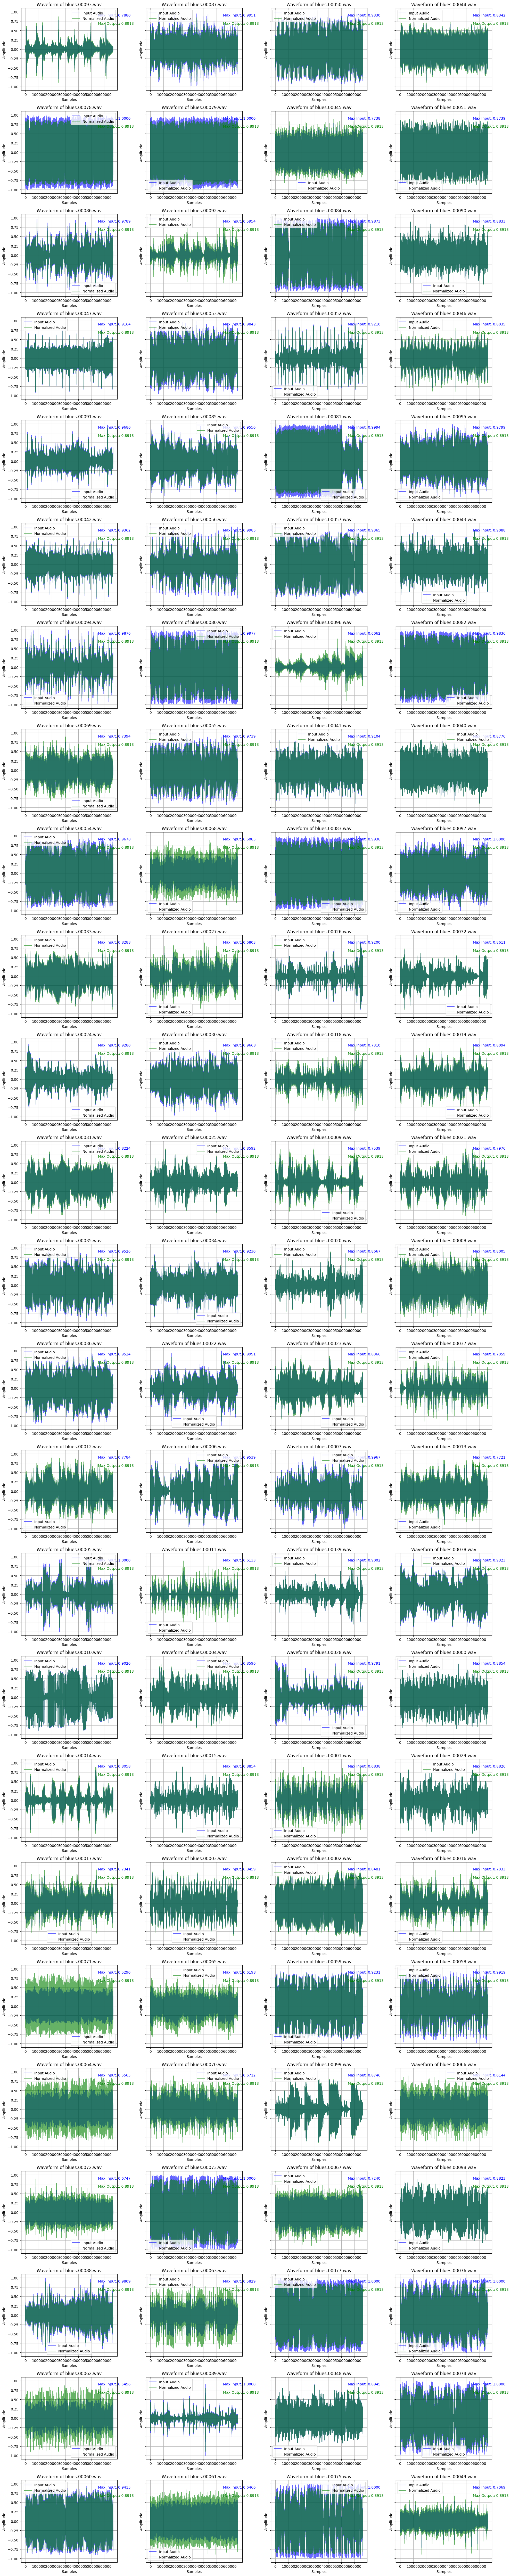

In [41]:
# Set your desired target peak level (e.g., -1 dB)
target_peak = -1.0  # Target peak normalization in dB

# Create lists to store the filenames and waveforms for plotting
input_waveforms = []
output_waveforms = []
filenames = []

# Iterate through all files in the directory (normalize each audio file)
for filename in os.listdir(input_directory):
    if filename.endswith(".wav"):  # Modify this to handle other formats (e.g., .mp3)
        input_path = os.path.join(input_directory, filename)
        output_path = os.path.join(output_directory, filename)

        try:
            # Load the original audio file
            audio_data, sr = librosa.load(input_path, sr=None)  # sr=None keeps the original sample rate
            
            # Peak normalize the audio to -1 dB (target_peak)
            peak_normalized_audio = pyln.normalize.peak(audio_data, target_peak)

            # Save the normalized audio to the output file
            sf.write(output_path, peak_normalized_audio, sr)

            # Append the waveforms for later plotting
            input_waveforms.append(audio_data)
            output_waveforms.append(peak_normalized_audio)
            filenames.append(filename)

        except Exception as e:
            print(f"Error processing {input_path}: {e}")

# Determine the number of files and rows required for the plot
n_files = len(filenames)
n_cols = 4  # Number of columns in the plot grid
n_rows = (n_files + n_cols - 1) // n_cols  # Calculate the number of rows

# Create a figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4), sharey=True)

# Flatten axes array for easy iteration if it's multidimensional
axes = axes.flatten()

# Plot each waveform (input and output) and display the max amplitude
for i in range(n_files):
    # Plot the input waveform
    axes[i].plot(input_waveforms[i], color='blue', alpha=0.6, label="Input Audio")
    axes[i].plot(output_waveforms[i], color='green', alpha=0.6, label="Normalized Audio")

    # Find the max amplitudes for both input and output
    input_max_amplitude = np.max(np.abs(input_waveforms[i]))
    output_max_amplitude = np.max(np.abs(output_waveforms[i]))

    # Display the max amplitude on the plot
    axes[i].text(0.8, 0.9, f"Max Input: {input_max_amplitude:.4f}", color='blue', transform=axes[i].transAxes)
    axes[i].text(0.8, 0.8, f"Max Output: {output_max_amplitude:.4f}", color='green', transform=axes[i].transAxes)

    axes[i].set_title(f"Waveform of {filenames[i]}")
    axes[i].set_xlabel("Samples")
    axes[i].set_ylabel("Amplitude")
    axes[i].grid(True)
    axes[i].legend()

# Adjust layout to prevent overlap and make space for titles and labels
plt.tight_layout()
plt.show()

In [43]:
#Denoise the audio files
# waveforms = []
denoised_waveforms = []
filenames = []
tmp_filecount = 0
tmp_maxfilecount = 12
# Iterate through all files in the directory (denoise each audio file)
for filename in os.listdir(input_directory):
    if tmp_filecount > tmp_maxfilecount:
        break
    tmp_filecount = tmp_filecount + 1
    if filename.endswith(".wav"):  # Modify this to handle other formats (e.g., .mp3)
        input_path = os.path.join(output_directory, filename)
        output_path = os.path.join('OutputData/Denoised/blues', filename)

        try:
            # Load the original audio file
            audio_data, sr = librosa.load(input_path, sr=None)  # sr=None keeps the original sample rate

            # Print the maximum amplitude before noise reduction
            original_max_amplitude = np.max(np.abs(audio_data))
            print(f"Original Max Amplitude for {filename}: {original_max_amplitude:.4f}")

            # Apply Noise Reduction with adjusted parameters
            audio_data_denoised = nr.reduce_noise(
                y=audio_data,          # The audio signal to process
                sr=sr,                 # Sample rate of the audio signal
                prop_decrease=0.8,     # Less aggressive noise reduction (0.8 means moderate reduction)
                time_mask_smooth_ms=200.0,  # Smoother time masking (200ms)
                freq_mask_smooth_hz=500.0,  # Smoother frequency masking (500Hz)
                n_fft=4096,            # Higher FFT size for better frequency resolution
                win_length=2048        # Default window length for analysis
            )

            # Print the maximum amplitude after noise reduction
            denoised_max_amplitude = np.max(np.abs(audio_data_denoised))
            print(f"Denoised Max Amplitude for {filename}: {denoised_max_amplitude:.4f}")

            # Save the denoised audio to the output file
            sf.write(output_path, audio_data_denoised, sr)

            # Append data for later plotting
            waveforms.append(audio_data)
            denoised_waveforms.append(audio_data_denoised)
            filenames.append(filename)

        except Exception as e:
            print(f"Error processing {input_path}: {e}")

# Determine the number of files and rows required for the plot
n_files = len(waveforms)
n_cols = 4  # Number of columns in the plot grid
n_rows = (n_files * 2 + n_cols - 1) // n_cols  # Calculate the number of rows for original and denoised plots

# Create a figure with subplots
fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 5, n_rows * 4), sharey=True)

# Flatten axes array for easy iteration if it's multidimensional
axes = axes.flatten()

# Plot each original and denoised waveform
for i in range(tmp_maxfilecount):
    # Plot original waveform
    axes[2 * i].plot(waveforms[i], color='blue', alpha=0.6)
    axes[2 * i].set_title(f"Original: {filenames[i]}")
    axes[2 * i].set_xlabel("Samples")
    axes[2 * i].set_ylabel("Amplitude")
    axes[2 * i].grid(True)

    # Plot denoised waveform
    axes[2 * i + 1].plot(denoised_waveforms[i], color='green', alpha=0.6)
    axes[2 * i + 1].set_title(f"Denoised: {filenames[i]}")
    axes[2 * i + 1].set_xlabel("Samples")
    axes[2 * i + 1].set_ylabel("Amplitude")
    axes[2 * i + 1].grid(True)

# Adjust layout to prevent overlapping labels
plt.tight_layout()

# Display the plots
plt.show()

Original Max Amplitude for blues.00093.wav: 0.8913
Denoised Max Amplitude for blues.00093.wav: 0.4327
Original Max Amplitude for blues.00087.wav: 0.8913
Denoised Max Amplitude for blues.00087.wav: 0.3602
Original Max Amplitude for blues.00050.wav: 0.8913
Denoised Max Amplitude for blues.00050.wav: 0.4495
Original Max Amplitude for blues.00044.wav: 0.8913
Denoised Max Amplitude for blues.00044.wav: 0.2423
Original Max Amplitude for blues.00078.wav: 0.8913
Denoised Max Amplitude for blues.00078.wav: 0.3037
Original Max Amplitude for blues.00079.wav: 0.8913
Denoised Max Amplitude for blues.00079.wav: 0.3409
Original Max Amplitude for blues.00045.wav: 0.8912
Denoised Max Amplitude for blues.00045.wav: 0.2255
Original Max Amplitude for blues.00051.wav: 0.8912
Denoised Max Amplitude for blues.00051.wav: 0.3316
Original Max Amplitude for blues.00086.wav: 0.8913
Denoised Max Amplitude for blues.00086.wav: 0.3347
Original Max Amplitude for blues.00092.wav: 0.8912
Denoised Max Amplitude for blue